# Housing affordability in Europe, 1975–2025

**Team:** Akshat Dayal, Bhavini Manot, Bo De Roeck
**Course:** AI Methods I – Day 1: Data cleaning and EDA

## 1. Introduction

**Use case:** When house prices grow faster than what people earn, buying a home gets harder. People move further out, flats get smaller, and cities need to build more and denser housing. We look at how house prices and incomes changed in 17 European countries over 50 years.

**Why only Europe:** We study at IAAC in Barcelona and want to understand the European housing market. This gives 867 rows (17 countries × 51 years), a bit fewer than the suggested 1,000. We accept that because a focused question is more useful to us.

### Tools
We load the libraries (ready-made tools) we need: pandas for tables, numpy for maths, matplotlib and seaborn for charts.

In [1]:
# Import the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed seed so results are the same every time
random_state = 42

# Helper to save each chart into the figures folder
def save_fig(name):
    plt.tight_layout()
    plt.savefig("../figures/" + name + ".png")

### Load the data
We read the CSV file from the data folder. Then we keep only the 17 European countries.

In [2]:
# Read the CSV file into a table called df
df = pd.read_csv("../data/accessibilit-economica-alloggi-26-paesi-1975-2025.csv")

# List of the European countries we want to keep
europe = ["Belgium", "Croatia", "Denmark", "Finland", "France", "Germany",
          "Ireland", "Italy", "Luxembourg", "Netherlands", "Norway", "Portugal",
          "Slovenia", "Spain", "Sweden", "Switzerland", "UK"]

# Keep only rows where the country is in our list
df = df[df["country"].isin(europe)]

# Check the size: (rows, columns)
print(df.shape)

(867, 8)


### First look
We look at the first rows, the column types, and simple statistics.

In [3]:
# Show the first 5 rows
df.head()

,country,iso,year,house_price_index,personal_disposable_income,real_house_price_index,real_personal_disposable_income,affordability_proxy
51,Belgium,BEL,1975,8.22,13.12,35.63,56.91,62.61
52,Belgium,BEL,1976,10.09,15.08,40.60,60.68,66.91
53,Belgium,BEL,1977,12.02,15.94,45.13,59.87,75.38
54,Belgium,BEL,1978,13.69,16.97,49.30,61.12,80.66
55,Belgium,BEL,1979,14.96,18.01,51.86,62.44,83.06


In [4]:
# Column names, types and how many values are filled
df.info()

<class 'pandas.DataFrame'>
Index: 867 entries, 51 to 1325
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   country                          867 non-null    str    
 1   iso                              867 non-null    str    
 2   year                             867 non-null    int64  
 3   house_price_index                867 non-null    float64
 4   personal_disposable_income       867 non-null    float64
 5   real_house_price_index           867 non-null    float64
 6   real_personal_disposable_income  867 non-null    float64
 7   affordability_proxy              867 non-null    float64
dtypes: float64(5), int64(1), str(2)
memory usage: 61.0 KB


In [5]:
# Simple statistics for the number columns
df.describe()

,year,house_price_index,personal_disposable_income,real_house_price_index,real_personal_disposable_income,affordability_proxy
count,867.000000,867.000000,867.000000,867.000000,867.000000,867.000000
mean,2000.000000,46.598604,47.265144,72.296390,74.220334,97.185525
std,14.728098,31.081924,27.488244,27.614585,17.677069,37.857460
min,1975.000000,0.000000,0.000000,16.140000,19.430000,37.300000
25%,1987.000000,18.980000,24.280000,51.040000,60.315000,76.830000
50%,2000.000000,44.470000,46.420000,70.930000,75.170000,97.110000
75%,2013.000000,68.575000,68.675000,94.970000,89.210000,107.940000
max,2025.000000,118.820000,106.490000,146.070000,104.730000,725.910000


### Dataset card

| | |
|---|---|
| **Source** | Kaggle: "Forecasting housing affordability to 2035" (https://www.kaggle.com/code/tolstoyjustin/forecasting-housing-affordability-to-2035/output) |
| **What one row is** | One country in one year |
| **Size** | 867 rows × 8 columns (17 European countries, 1975–2025) |
| **Licence** | CC BY-SA 4.0 |
| **Limits** | The numbers are indices, not prices in euros. They show how prices changed over time inside one country, so we cannot say which country is the most expensive. |

### Data dictionary

| Column | Meaning |
|---|---|
| `country` | Country name |
| `iso` | 3-letter country code (e.g. ESP = Spain) |
| `year` | Year |
| `house_price_index` | House prices (not adjusted for inflation) |
| `personal_disposable_income` | What people earn after tax (not adjusted for inflation) |
| `real_house_price_index` | House prices, adjusted for inflation |
| `real_personal_disposable_income` | Income after tax, adjusted for inflation |
| `affordability_proxy` | House prices ÷ income × 100. **Higher = harder to afford** |

## 1. Data quality check and cleaning

### 1.1 Duplicates
We check if any row appears twice.

In [6]:
# Count rows that are exact copies
print(df.duplicated().sum())

# Count if the same country and year appear twice
print(df.duplicated(subset=["country", "year"]).sum())

0
0


No duplicates. Every country has one row for each year.

### 1.2 Missing values
We check for empty values, and also for zeros, because a price or income index should never be 0.

In [7]:
# Count empty values in each column
print(df.isna().sum())

# Count zeros in each column
print((df == 0).sum())

country                            0
iso                                0
year                               0
house_price_index                  0
personal_disposable_income         0
real_house_price_index             0
real_personal_disposable_income    0
affordability_proxy                0
dtype: int64
country                             0
iso                                 0
year                                0
house_price_index                  27
personal_disposable_income         26
real_house_price_index              0
real_personal_disposable_income     0
affordability_proxy                 0
dtype: int64


In [8]:
# Which countries and years have a zero house price?
zeros = df[df["house_price_index"] == 0]
print(zeros[["country", "year"]])

       country  year
1071   Croatia  1975
1072   Croatia  1976
1073   Croatia  1977
1074   Croatia  1978
1075   Croatia  1979
1076   Croatia  1980
1077   Croatia  1981
1078   Croatia  1982
1079   Croatia  1983
1080   Croatia  1984
1081   Croatia  1985
1082   Croatia  1986
1083   Croatia  1987
1084   Croatia  1988
1173  Slovenia  1975
1174  Slovenia  1976
1175  Slovenia  1977
1176  Slovenia  1978
1177  Slovenia  1979
1178  Slovenia  1980
1179  Slovenia  1981
1180  Slovenia  1982
1181  Slovenia  1983
1182  Slovenia  1984
1183  Slovenia  1985
1184  Slovenia  1986
1185  Slovenia  1987


In [9]:
# The real columns still have values for the same years
croatia = df[df["country"] == "Croatia"]
print(croatia[["year", "house_price_index", "real_house_price_index"]].head(16))

      year  house_price_index  real_house_price_index
1071  1975               0.00                   63.78
1072  1976               0.00                   72.46
1073  1977               0.00                   81.48
1074  1978               0.00                   84.57
1075  1979               0.00                   82.93
1076  1980               0.00                   75.34
1077  1981               0.00                   68.50
1078  1982               0.00                   69.87
1079  1983               0.00                   63.25
1080  1984               0.00                   53.29
1081  1985               0.00                   53.98
1082  1986               0.00                   52.35
1083  1987               0.00                   62.05
1084  1988               0.00                   69.23
1085  1989               0.01                   56.14
1086  1990               0.06                   63.52


We found 27 zeros in house_price_index (Croatia 1975–1988 and Slovenia 1975–1987). An index can't really be 0. These countries had hyperinflation in the 1980s, so the old values became very small and were rounded to 0.00 when the data was saved with 2 decimals.

Decision: we change these zeros to missing values (NaN) instead of deleting the rows, because the real (inflation-adjusted) columns for those years still have proper values. For the rest of the analysis we use the real columns.

In [10]:
# Replace the fake zeros with NaN (missing)
df["house_price_index"] = df["house_price_index"].replace(0, np.nan)
df["personal_disposable_income"] = df["personal_disposable_income"].replace(0, np.nan)

# Check: zeros should now be gone
print((df == 0).sum())

country                            0
iso                                0
year                               0
house_price_index                  0
personal_disposable_income         0
real_house_price_index             0
real_personal_disposable_income    0
affordability_proxy                0
dtype: int64


### 1.3 Data types
We check that numbers are stored as numbers and text as text, and that each country is spelled only one way.

In [11]:
# Type of each column
print(df.dtypes)

country                                str
iso                                    str
year                                 int64
house_price_index                  float64
personal_disposable_income         float64
real_house_price_index             float64
real_personal_disposable_income    float64
affordability_proxy                float64
dtype: object


In [12]:
# Each country should appear only once in this list
print(df["country"].unique())
print(df["country"].nunique())

<StringArray>
[    'Belgium', 'Switzerland',     'Germany',     'Denmark',       'Spain',
     'Finland',      'France',          'UK',     'Ireland',       'Italy',
  'Luxembourg', 'Netherlands',      'Norway',      'Sweden',     'Croatia',
    'Slovenia',    'Portugal']
Length: 17, dtype: str
17


All types are correct: text for country and code, whole numbers for year, decimals for the indices. There are 17 country names and no spelling mistakes, so nothing needs fixing here.

### 1.4 Outliers
We look for unusually high values of affordability_proxy with a boxplot, and check if they are mistakes or real events.

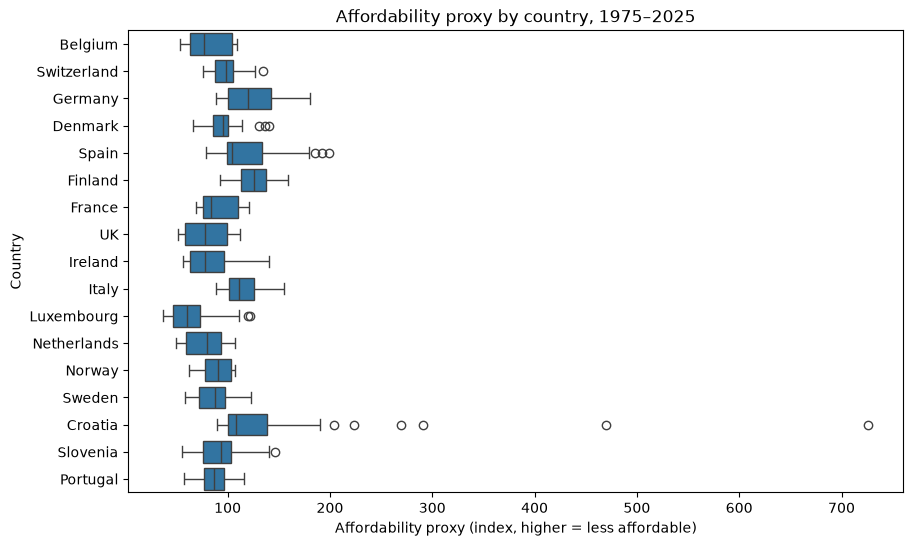

In [13]:
import os
os.makedirs("../figures", exist_ok=True)   # make the figures folder if it isn't there
# Boxplot of affordability for each country
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="affordability_proxy", y="country")
plt.title("Affordability proxy by country, 1975–2025")
plt.xlabel("Affordability proxy (index, higher = less affordable)")
plt.ylabel("Country")
plt.savefig("../figures/01_outliers_boxplot.png")
plt.show()

In [14]:
# Find values far above normal (IQR rule)
q1 = df["affordability_proxy"].quantile(0.25)
q3 = df["affordability_proxy"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Upper limit:", upper)

outliers = df[df["affordability_proxy"] > upper]
print(outliers.groupby("country")["year"].agg(["min", "max", "count"]))

Upper limit: 154.605
          min   max  count
country                   
Croatia  1991  2000     10
Finland  1989  1989      1
Germany  1975  1985     11
Italy    1975  1975      1
Spain    1975  2007      8


We found 31 values above the IQR upper limit (154.6), mostly Croatia 1991–2000, Germany 1975–1985 and Spain (including 2007).

These are not mistakes. They match real events: the war and hyperinflation in Croatia in the 1990s, the Spanish housing bubble before 2008, the Finnish bubble in 1989, and much lower incomes in the 1970s compared to today.

Decision: we keep all of them because they are real. We add a column that marks them, so we can leave them out later if needed (for example, for modelling on Day 2).

In [15]:
# Mark the outliers with True / False
df["is_outlier"] = df["affordability_proxy"] > upper

# Check how many are marked
print(df["is_outlier"].sum())

31


### 1.5 New columns (feature engineering)
We create three new columns:
- price_growth: yearly % change in real house prices
- income_growth: yearly % change in real income
- gap: price_growth minus income_growth. If it is positive, house prices grew faster than incomes that year, so housing became harder to afford.

For architecture this is important: when prices keep growing faster than incomes, people can afford less space, which pushes cities towards smaller flats and higher density.

In [16]:
# Sort by country and year so each year follows the previous one
df = df.sort_values(["country", "year"])

# Yearly % change, calculated separately for each country
df["price_growth"] = df.groupby("country")["real_house_price_index"].pct_change() * 100
df["income_growth"] = df.groupby("country")["real_personal_disposable_income"].pct_change() * 100

# Gap: positive = prices grew faster than incomes
df["gap"] = df["price_growth"] - df["income_growth"]

# Look at the new columns for Spain
print(df[df["country"] == "Spain"][["year", "price_growth", "income_growth", "gap"]].tail(10))

     year  price_growth  income_growth       gap
347  2016      1.662283       2.820173 -1.157890
348  2017      0.848598       1.398301 -0.549703
349  2018      1.980503       1.368410  0.612093
350  2019      2.042665       1.140645  0.902020
351  2020     -1.143871       0.548370 -1.692242
352  2021     -0.039900       1.090759 -1.130660
353  2022     -1.486878      -1.598127  0.111249
354  2023     -1.256078       1.137892 -2.393970
355  2024      2.585146       2.280863  0.304282
356  2025      8.170000      -0.780000  8.950000


### 1.6 Summary of cleaning decisions

| Check | What we found | What we did |
|---|---|---|
| Duplicates | None | Nothing needed |
| Missing values | No empty cells, but 27 fake zeros (Croatia and Slovenia, 1975–1988) | Changed them to NaN and used the real columns instead |
| Data types | All correct, 17 countries spelled one way | Nothing needed |
| Outliers | 31 very high values (Croatia 1990s, Spain 2007, Germany 1970s) | Kept them because they are real events, and marked them in is_outlier |
| New columns | – | Added price_growth, income_growth and gap |

In [17]:
# Make the data folder if it isn't there, then save the clean table
os.makedirs("../data", exist_ok=True)
df.to_csv("../data/housing_europe_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (867, 12)


## 2. Exploratory Data Analysis

### 2.1 Descriptive statistics
We look at the averages and spread of the main columns, using data from 2000 onwards.

In [18]:
# Statistics of the main columns
print(df[["real_house_price_index", "real_personal_disposable_income", "affordability_proxy", "price_growth", "income_growth", "gap"]].describe())

# Typical yearly growth since 2000
recent = df[df["year"] >= 2000]
print("Median price growth:", recent["price_growth"].median())
print("Median income growth:", recent["income_growth"].median())
print("Share of years where prices grew faster:", (recent["gap"] > 0).mean())

       real_house_price_index  real_personal_disposable_income  \
count              867.000000                       867.000000   
mean                72.296390                        74.220334   
std                 27.614585                        17.677069   
min                 16.140000                        19.430000   
25%                 51.040000                        60.315000   
50%                 70.930000                        75.170000   
75%                 94.970000                        89.210000   
max                146.070000                       104.730000   

       affordability_proxy  price_growth  income_growth         gap  
count           867.000000    850.000000     850.000000  850.000000  
mean             97.185525      1.862642       1.395248    0.467395  
std              37.857460      7.609665       4.101397    8.178067  
min              37.300000    -35.543486     -45.765065  -45.410798  
25%              76.830000     -2.109310      -0.073997

Since 2000, real house prices grew about 1.96% per year and real incomes about 1.28% per year in the median country. Prices grew faster than incomes in 57% of the years. The difference looks small, but it adds up every year. House price growth also jumps around much more than income growth.

### 2.2 Univariate analysis
We look at how price growth and income growth are spread out.

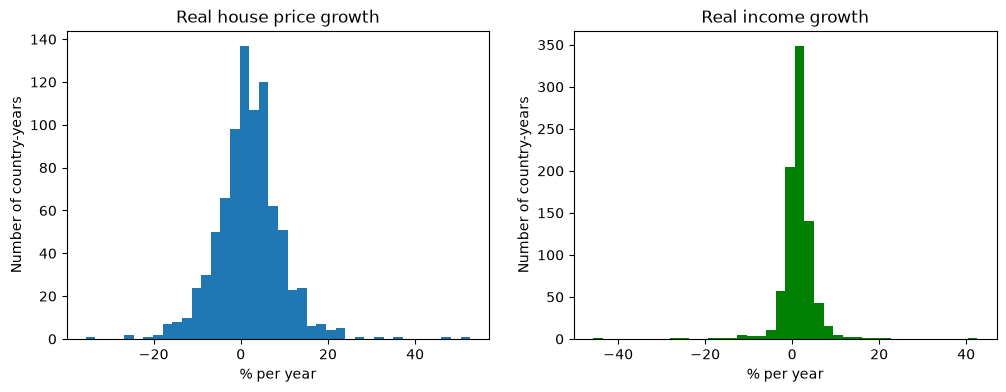

In [19]:
# Histograms: how often each growth value appears
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df["price_growth"].dropna(), bins=40)
plt.title("Real house price growth")
plt.xlabel("% per year")
plt.ylabel("Number of country-years")

plt.subplot(1, 2, 2)
plt.hist(df["income_growth"].dropna(), bins=40, color="green")
plt.title("Real income growth")
plt.xlabel("% per year")
plt.ylabel("Number of country-years")

plt.savefig("../figures/02_distributions.png")
plt.show()

Income growth stays close to 1–2% most years. House price growth is much wider: some years prices jump more than 20%, and in crashes they fall a lot. So house prices are much less stable than incomes.

### 2.3 Bivariate analysis
Do house prices go up when incomes go up? We plot one against the other.

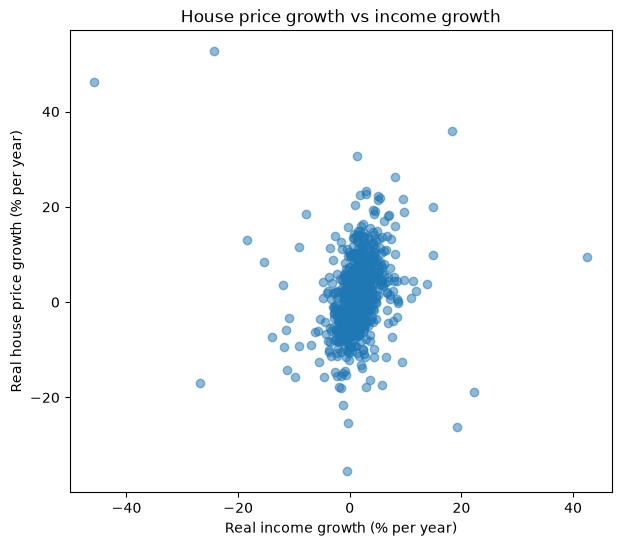

Correlation: 0.1257226823349293


In [20]:
# Scatter plot: each dot is one country in one year
plt.figure(figsize=(7, 6))
plt.scatter(df["income_growth"], df["price_growth"], alpha=0.5)
plt.title("House price growth vs income growth")
plt.xlabel("Real income growth (% per year)")
plt.ylabel("Real house price growth (% per year)")
plt.savefig("../figures/03_prices_vs_incomes.png")
plt.show()

print("Correlation:", df["income_growth"].corr(df["price_growth"]))

The dots form a cloud, not a line. The correlation is only about 0.13, which is very weak. This means house prices do not simply follow incomes from year to year. Other things, like interest rates, loans and how many houses are built, probably matter more, but they are not in this dataset.

### 2.4 Grouped comparisons
We compare the average gap (price growth minus income growth) by decade.

decade
1970s    0.529329
1980s   -0.061600
1990s   -0.032180
2000s    2.093583
2010s   -0.170038
2020s    0.492460
Name: gap, dtype: float64


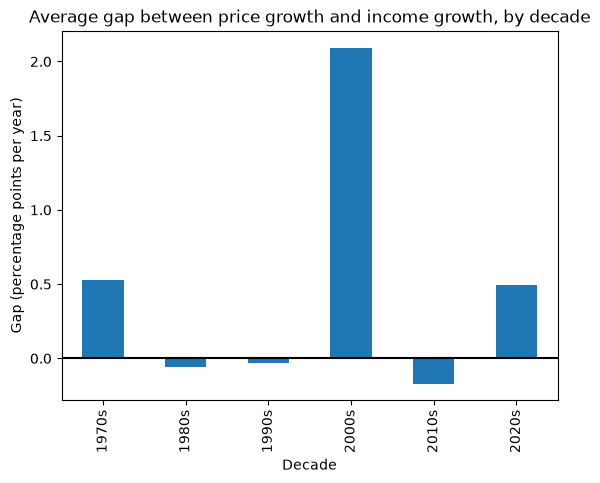

In [21]:
# Make a decade column, e.g. 2000s
df["decade"] = (df["year"] // 10 * 10).astype(str) + "s"

# Average gap per decade
gap_decade = df.groupby("decade")["gap"].mean()
print(gap_decade)

gap_decade.plot(kind="bar")
plt.title("Average gap between price growth and income growth, by decade")
plt.xlabel("Decade")
plt.ylabel("Gap (percentage points per year)")
plt.axhline(0, color="black")
plt.savefig("../figures/04_gap_by_decade.png")
plt.show()

The 2000s stand out: prices grew about 2.1 percentage points per year faster than incomes, which was the housing boom before the 2008 crisis. In the 2010s it went slightly negative, so housing became a bit more affordable after the crash. In the 2020s the gap is positive again (about 0.5), so affordability is getting worse again.

### 2.5 Correlation
We check which numeric columns move together.

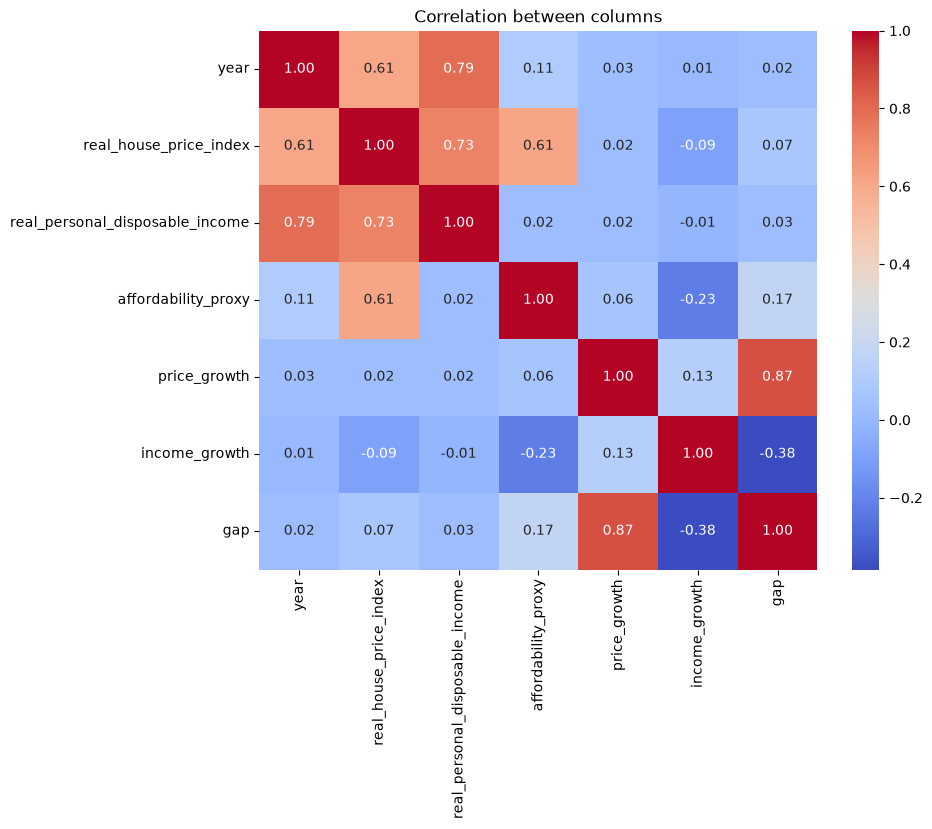

In [22]:
# Correlation heatmap
cols = ["year", "real_house_price_index", "real_personal_disposable_income", "affordability_proxy", "price_growth", "income_growth", "gap"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between columns")
plt.savefig("../figures/05_correlation.png")
plt.show()

affordability_proxy is linked to real house prices (0.61) but hardly to real income (0.02), so in this data affordability moves mainly with house prices. gap is strongly linked to price_growth (0.87), but that is expected because we calculated gap from it. Correlation does not mean causation: two things can move together without one causing the other. For example, year and income are linked (0.79) because economies grew over time, not because time causes income.

### 2.6 Question 1: Since 2000, where did housing become harder to afford?
We compare each country's affordability_proxy in 2025 with 2000.

country
Croatia        -33.851500
Finland        -17.177440
Germany        -12.957502
Italy           -1.656151
Ireland          4.108743
Slovenia         5.465877
Denmark          7.487127
Netherlands     20.858469
Spain           21.403118
Norway          22.875337
Switzerland     34.415154
Sweden          34.812569
Portugal        34.832503
France          35.336927
Belgium         36.963064
UK              44.308231
Luxembourg     104.929577
dtype: float64


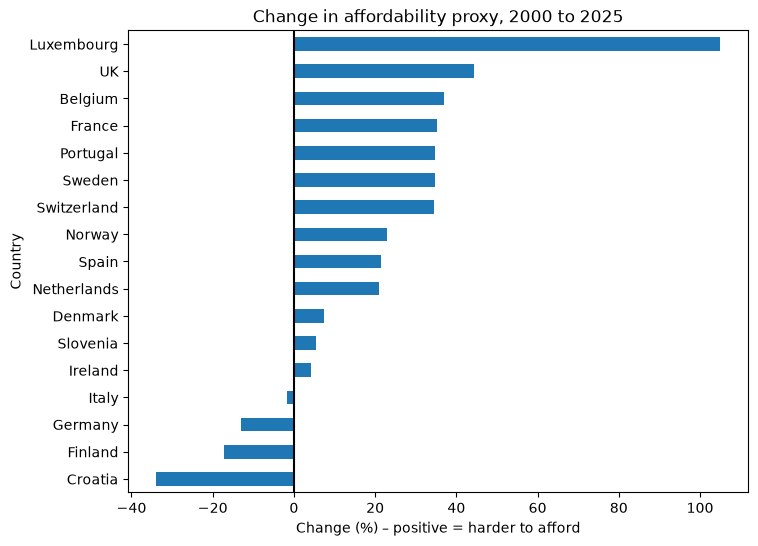

In [23]:
# Put years as columns, countries as rows
table = df.pivot(index="country", columns="year", values="affordability_proxy")

# % change from 2000 to 2025
change = (table[2025] / table[2000] - 1) * 100
change = change.sort_values()
print(change)

change.plot(kind="barh", figsize=(8, 6))
plt.title("Change in affordability proxy, 2000 to 2025")
plt.xlabel("Change (%) – positive = harder to afford")
plt.ylabel("Country")
plt.axvline(0, color="black")
plt.savefig("../figures/06_q1_change.png")
plt.show()

Housing became harder to afford in 13 of the 17 countries. Luxembourg is by far the worst (+105%), followed by the UK (+44%), Belgium (+37%) and France (+35%). Only four countries improved: Croatia (−34%), Finland (−17%), Germany (−13%) and Italy (−2%).

This matters for architecture because in countries like Luxembourg and the UK people can afford less space, which increases demand for smaller and denser housing.

Limits: we only compare two years, and national averages hide big differences between cities and rural areas.

### 2.7 Question 2: Did the 2008 crisis make housing affordable again?
We follow affordability over time in Spain and Ireland (big housing bubbles) and Germany (no bubble).

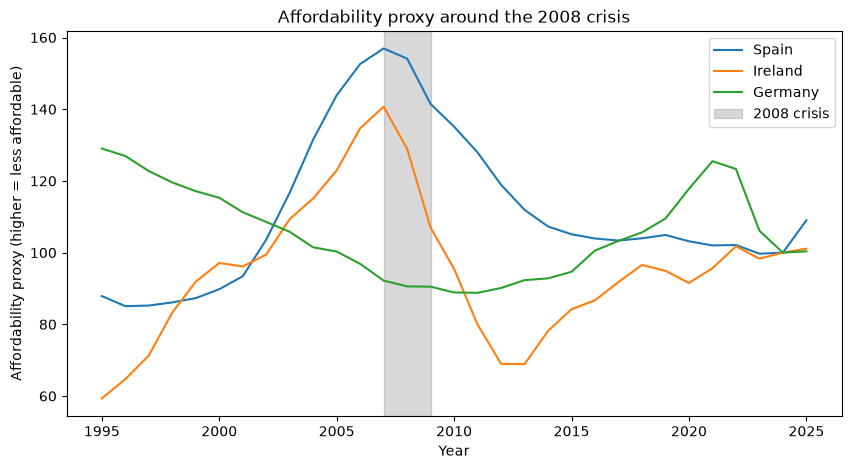

In [24]:
plt.figure(figsize=(10, 5))
for c in ["Spain", "Ireland", "Germany"]:
    one = df[(df["country"] == c) & (df["year"] >= 1995)]
    plt.plot(one["year"], one["affordability_proxy"], label=c)

plt.axvspan(2007, 2009, color="grey", alpha=0.3, label="2008 crisis")
plt.title("Affordability proxy around the 2008 crisis")
plt.xlabel("Year")
plt.ylabel("Affordability proxy (higher = less affordable)")
plt.legend()
plt.savefig("../figures/07_q2_crisis.png")
plt.show()

Spain and Ireland reached a peak in 2007 (about 157 and 141), then fell sharply after the crisis. Ireland dropped to about 69 by 2013, roughly half. Spain fell more slowly, reaching about 103 only in 2020. Germany did the opposite: it became cheaper in the 2000s and then rose to about 126 in 2021, before falling again.

So the crisis did make housing more affordable in the bubble countries, but only for some years. By 2025 all three are back around 100–109.

Limits: we can see the change but not the reasons. Interest rates and the number of new houses built are not in the data.

### 2.8 Question 3: Is Spain becoming harder to afford than other European countries?
We compare Spain with the median of all 17 countries.

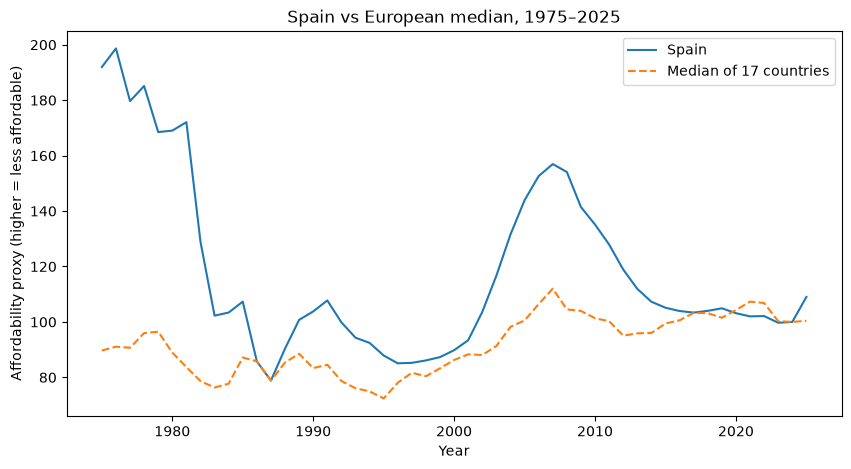

In [25]:
# Median of all countries per year
median = df.groupby("year")["affordability_proxy"].median()
spain = df[df["country"] == "Spain"]

plt.figure(figsize=(10, 5))
plt.plot(spain["year"], spain["affordability_proxy"], label="Spain")
plt.plot(median.index, median.values, label="Median of 17 countries", linestyle="--")
plt.title("Spain vs European median, 1975–2025")
plt.xlabel("Year")
plt.ylabel("Affordability proxy (higher = less affordable)")
plt.legend()
plt.savefig("../figures/08_q3_spain.png")
plt.show()

Spain has been less affordable than the European median for most of the period. The difference was largest in the late 1970s (around 200 vs 90) and again during the housing bubble, peaking in 2007 (157 vs 112). After the crisis Spain moved close to the median, but in 2025 it is above it again (109 vs 100), after prices jumped about 8% in one year while incomes fell.

For us in Barcelona this suggests that housing pressure in Spain is rising again. But this is a national average: big cities and tourist areas are probably much worse, and the data does not include rents.

## 3. Conclusions

### Key findings
- Housing became harder to afford in 13 of 17 European countries between 2000 and 2025. Luxembourg is the worst (+105%), followed by the UK (+44%) and Belgium (+37%). Croatia, Finland, Germany and Italy improved.
- Since 2000, real house prices grew about 1.96% per year and real incomes about 1.28% per year in the median country. Prices grew faster in 57% of the years.
- From year to year, house price growth is only weakly linked to income growth (correlation 0.13), so other factors drive prices.
- The 2000s were the boom decade: prices grew about 2.1 points per year faster than incomes. The 2008 crisis brought affordability down in Spain and Ireland, but only for some years.
- In the 2020s prices are again growing faster than incomes, and Spain had a big jump in 2025.

### Limitations
- The values are indices, not prices in euros, so we cannot say which country is the most expensive.
- National averages hide big differences between cities like Barcelona and the rest of the country.
- There is no data on rents, interest rates or new housing construction, so we can describe trends but not explain them.
- We kept only 17 European countries, so the dataset has 867 rows, fewer than the suggested 1,000.
- The early nominal values for Croatia and Slovenia were set to NaN, and 31 outliers are marked but kept.
- The 2025 values may still be estimates.

### Ready for modelling
- A possible target is affordability_proxy for the next year.
- We should not use real_house_price_index and real_personal_disposable_income of the same year as inputs, because affordability_proxy is calculated from them (leakage). The same goes for price_growth, income_growth and gap of the same year.
- We should only use values from previous years, and split the data by time (train on older years, test on newer years).